# Logistic regression vs random forest

Two algorithms on the same problem: classify Fakeddit posts as **fake (0)** or **real (1)** from the title and three engagement numbers. Both models get exactly the same data and the same feature preparation as `01_ml_model.ipynb`; only the classifier differs.

In [1]:
import gc, time, numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from pathlib import Path
from scipy.stats import binomtest  # tikrina, ar dvieju modeliu skirtumas nera tik atsitiktinumas
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier  # daug sprendimu medziu, kurie balsuoja uz atsakyma
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

DATA = Path("../data/multimodal_only_samples-20261006T085257Z-1-001/multimodal_only_samples")
FIG = Path("../report/figures"); FIG.mkdir(parents=True, exist_ok=True)  # grafikus iskart saugom ataskaitai
SEED = 42

## 1. Load data
Same columns and the same official splits as the first notebook: all 564,000 training and 59,319 test posts. `subreddit` is not loaded because it gives away the label.

In [2]:
FEATURES = ["clean_title", "score", "num_comments", "upvote_ratio"]
train = pd.read_csv(DATA / "multimodal_train.tsv", sep="\t", usecols=FEATURES + ["2_way_label"])
test = pd.read_csv(DATA / "multimodal_test_public.tsv", sep="\t", usecols=FEATURES + ["2_way_label"])
X_train, y_train = train[FEATURES], train["2_way_label"]
X_test, y_test = test[FEATURES], test["2_way_label"]
X_train.shape, X_test.shape

((564000, 4), (59319, 4))

## 2. Two models, one preparation
The logistic regression pipeline saved by the first notebook is cloned: same settings, not yet trained. The random forest pipeline is the same clone with only the last step swapped, so any difference in results comes from the algorithm, not from the features (TF-IDF on the title + three cleaned numbers).

In [3]:
logreg = clone(joblib.load("../models/logreg_tfidf.joblib"))  # tie patys nustatymai kaip pirmame darbe, bet dar neismokytas
forest = clone(logreg).set_params(clf=RandomForestClassifier(
    n_estimators=50, class_weight="balanced", n_jobs=4, random_state=SEED))  # medziai auga iki galo: bandant juos apriboti tikslumas krito; 4 branduoliai, kad kompiuteris neuzstrigtu
specs = {"Logistic regression": clone(logreg), "Random forest": clone(forest)}  # neismokytos kopijos kryzminei patikrai
models = {"Logistic regression": logreg, "Random forest": forest}
RF_PATH = Path("../models/random_forest_tfidf.joblib")
CV_PATH = Path("../models/cv_scores.csv")

## 3. Train and predict
Training and prediction time are measured too: a slower or bigger model has to earn its place.

The forest takes about 12 minutes to train, so after the first run it is saved to `models/random_forest_tfidf.joblib` and later runs load it instead (delete the file to retrain). Its training time is stored inside the saved model. The file is about 1.2 GB, over GitHub's 100 MB limit, so it is kept locally and listed in `.gitignore`. Load it with `joblib.load` and call `.predict()` on a DataFrame with the four feature columns, same as the logistic regression. Logistic regression trains in about 20 seconds, so it is simply trained every time.

In [4]:
res = {}
for name in models:
    if name == "Random forest" and RF_PATH.exists():
        models[name] = joblib.load(RF_PATH)  # jau ismokytas ir issaugotas, nemokom is naujo
    else:
        t = time.perf_counter(); models[name].fit(X_train, y_train)
        models[name].fit_seconds_ = time.perf_counter() - t  # mokymo laika saugom paciame modelyje, kad liktu ir ikelus is failo
        if name == "Random forest": joblib.dump(models[name], RF_PATH)
    m = models[name]
    t = time.perf_counter(); proba = m.predict_proba(X_test); pred_s = time.perf_counter() - t
    res[name] = dict(proba=proba[:, 1], pred=proba.argmax(1), fit_s=m.fit_seconds_, pred_s=pred_s)  # pred: klase su didesne tikimybe, kaip daro predict()
    print(f"{name}: train {m.fit_seconds_:.0f} s, predict {pred_s:.1f} s")
logreg, forest = models.values()

Logistic regression: train 23 s, predict 0.6 s


Random forest: train 706 s, predict 4.3 s


In [5]:
for name, path in [("Logistic regression", Path("../models/logreg_tfidf.joblib")), ("Random forest", RF_PATH)]:  # regresijos failas is pirmo darbo: tie patys nustatymai ir duomenys
    res[name]["size_mb"] = path.stat().st_size / 2**20
    print(f"{name}: {res[name]['size_mb']:,.0f} MB")

Logistic regression: 2 MB
Random forest: 1,228 MB


## 4. Metrics
60% of test posts are fake, so accuracy alone flatters a model that leans towards "fake". **Macro F1** is the main metric: it weights both classes equally. **ROC-AUC** shows how well each model ranks posts regardless of the 0.5 threshold.

In [6]:
rows = {}
for name, r in res.items():
    p, rc, f, _ = precision_recall_fscore_support(y_test, r["pred"])
    rows[name] = {"accuracy": accuracy_score(y_test, r["pred"]), "macro F1": f.mean(), "ROC-AUC": roc_auc_score(y_test, r["proba"]),
                  "fake precision": p[0], "fake recall": rc[0], "real precision": p[1], "real recall": rc[1],
                  "train s": r["fit_s"], "predict s": r["pred_s"], "file MB": r["size_mb"]}
table = pd.DataFrame(rows).T
print("Majority-class baseline accuracy:", round((y_test == 0).mean(), 4))  # palyginimui: kiek gautum visada spedamas 'netikra'
table.round(4)

Majority-class baseline accuracy: 0.6037


,accuracy,macro F1,ROC-AUC,fake precision,fake recall,real precision,real recall,train s,predict s,file MB
Logistic regression,0.8487,0.8441,0.9226,0.8980,0.8454,0.7837,0.8537,23.3123,0.6028,2.2563
Random forest,0.8700,0.8647,0.9433,0.8995,0.8834,0.8270,0.8496,706.0807,4.2717,1228.1665


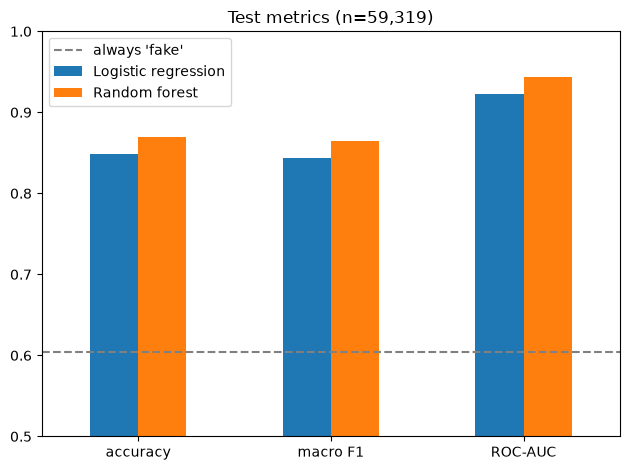

In [7]:
table[["accuracy", "macro F1", "ROC-AUC"]].T.plot.bar(rot=0, ylim=(0.5, 1), title="Test metrics (n=59,319)")
plt.axhline((y_test == 0).mean(), ls="--", c="gray", label="always 'fake'"); plt.legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "cmp_metrics.png", dpi=120); plt.show()

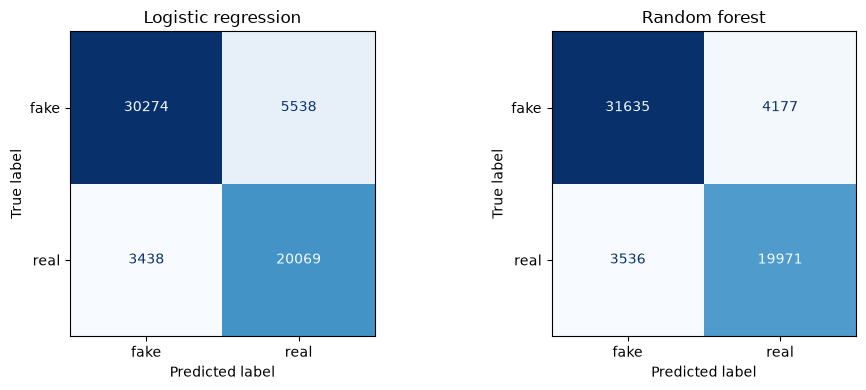

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, r) in zip(axes, res.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, r["pred"], display_labels=["fake", "real"], cmap="Blues", values_format="d", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig(FIG / "cmp_confusion.png", dpi=120); plt.show()

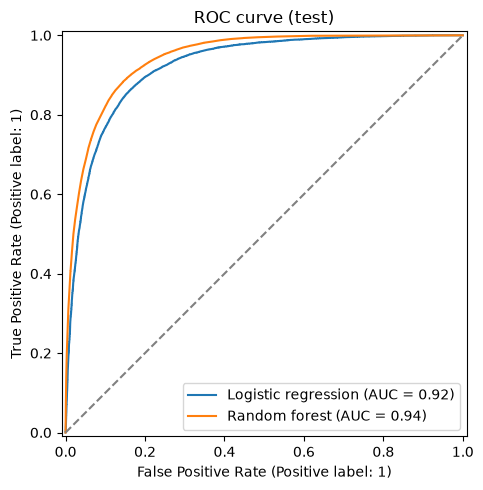

In [9]:
ax = plt.figure(figsize=(5, 5)).gca()
for name, r in res.items():
    RocCurveDisplay.from_predictions(y_test, r["proba"], name=name, ax=ax)
ax.plot([0, 1], [0, 1], ls="--", c="gray"); ax.set_title("ROC curve (test)")  # istrizaine = spejimas aklai
plt.tight_layout(); plt.savefig(FIG / "cmp_roc.png", dpi=120); plt.show()

## 5. Is the difference real?
Both models are scored on the same 59,319 posts, so their answers can be compared post by post.
* **McNemar's test** looks only at posts where exactly one model is right. If the models were equally good, each would win about half of them.
* **Bootstrap**: the test set is resampled 1,000 times to get a 95% interval for the gap in accuracy and macro F1.

In [10]:
y = y_test.to_numpy()
lr_pred, rf_pred = res["Logistic regression"]["pred"], res["Random forest"]["pred"]
lr_ok, rf_ok = lr_pred == y, rf_pred == y
print(pd.crosstab(lr_ok, rf_ok, rownames=["LR right"], colnames=["RF right"]))  # kur abu teisus, abu klysta ar teisus tik vienas
only_rf, only_lr = (rf_ok & ~lr_ok).sum(), (lr_ok & ~rf_ok).sum()
print(f"\nOnly RF right: {only_rf}, only LR right: {only_lr}")
print("McNemar p-value:", binomtest(only_rf, only_rf + only_lr, 0.5).pvalue)  # labai mazas skaicius = skirtumas ne atsitiktinis

RF right  False  True 
LR right              
False      4246   4730
True       3467  46876

Only RF right: 4730, only LR right: 3467
McNemar p-value: 2.491176249492384e-44


In [11]:
rng = np.random.default_rng(SEED)
gaps = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))  # traukiam testo irasus atsitiktinai su pasikartojimais, lyg turetume nauja testa
    gaps.append([accuracy_score(y[i], rf_pred[i]) - accuracy_score(y[i], lr_pred[i]),
                 f1_score(y[i], rf_pred[i], average="macro") - f1_score(y[i], lr_pred[i], average="macro")])
gaps = pd.DataFrame(gaps, columns=["accuracy gap", "macro F1 gap"])  # teigiamas skaicius = miskas geresnis
gaps.quantile([0.025, 0.5, 0.975]).round(4)

,accuracy gap,macro F1 gap
0.025,0.0184,0.0177
0.500,0.0211,0.0205
0.975,0.0241,0.0236


### Where does the gap come from?
The engagement numbers are missing for every post from one fake subreddit (`psbattle_artwork`) and get filled with the median. A tree can pick out that exact filled-in value, a straight-line model cannot. So accuracy is checked separately for test posts with and without missing numbers.

In [12]:
missing = X_test["num_comments"].isna().to_numpy()  # tusti langeliai yra tik viename netikrame subreddit
rows = {}
for label, m in [(f"numbers missing (n={missing.sum():,})", missing), (f"numbers present (n={(~missing).sum():,})", ~missing)]:
    b, c = (rf_ok & ~lr_ok)[m].sum(), (lr_ok & ~rf_ok)[m].sum()
    rows[label] = {"LR accuracy": lr_ok[m].mean(), "RF accuracy": rf_ok[m].mean(), "only RF right": b, "only LR right": c,
                   "McNemar p": binomtest(b, b + c, 0.5).pvalue}
print("Macro F1 where numbers are present - LR:", round(f1_score(y[~missing], lr_pred[~missing], average="macro"), 4),
      "RF:", round(f1_score(y[~missing], rf_pred[~missing], average="macro"), 4))  # ten, kur yra abi klases; tusciu langeliu grupeje visi irasai netikri
pd.DataFrame(rows).T.round(4)

Macro F1 where numbers are present - LR: 0.8143 RF: 0.813


,LR accuracy,RF accuracy,only RF right,only LR right,McNemar p
"numbers missing (n=17,472)",0.9221,0.9980,1333.0,7.0,0.000
"numbers present (n=41,847)",0.8180,0.8165,3397.0,3460.0,0.454


## 6. What the forest looks at
Logistic regression gives every word one signed weight (see the first notebook). The forest only says how much each feature was used for splitting, not whether it pushes towards fake or real.

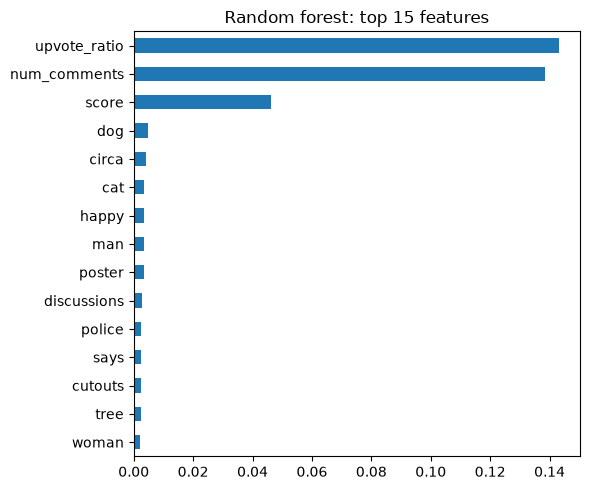

meta__upvote_ratio    0.1431
meta__num_comments    0.1386
meta__score           0.0463
title__dog            0.0049
title__circa          0.0043
title__cat            0.0036
title__happy          0.0035
title__man            0.0034
title__poster         0.0033
title__discussions    0.0028
title__police         0.0026
title__says           0.0026
title__cutouts        0.0025
title__tree           0.0023
title__woman          0.0023
dtype: float64

In [13]:
names = forest.named_steps["features"].get_feature_names_out()
imp = pd.Series(forest.named_steps["clf"].feature_importances_, index=names).nlargest(15)  # kiek kiekvienas stulpelis padejo medziams atskirti klases
imp.rename(lambda s: s.split("__", 1)[1]).sort_values().plot.barh(figsize=(6, 5), title="Random forest: top 15 features")
plt.tight_layout(); plt.savefig(FIG / "cmp_rf_importance.png", dpi=120); plt.show()
imp.round(4)

## 7. Cross-validation
The test set is a single split. 5-fold cross-validation on the training set trains each model five times, each time on 4/5 of the posts, and scores it on the remaining 1/5. This shows how much the scores move from one split to another. Both models use exactly the same folds, so their scores can be compared fold by fold.

To save memory, the final forest is dropped first (it is already saved), and the folds run one after another, with each fold's model thrown away after scoring. That way only one forest is in memory at a time.

Cross-validation takes about 40 minutes, so the fold scores are saved to `models/cv_scores.csv` and later runs load them (delete the file to recompute).

In [14]:
if CV_PATH.exists():
    cv_all = pd.read_csv(CV_PATH, index_col=["model", "fold"])  # jau suskaiciuota, nemokom 10 modeliu is naujo
else:
    del forest; gc.collect()  # galutinis miskas jau faile, o naujiems miskams reikia vietos
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # kiekvienoje dalyje toks pat netikru ir tikru santykis
    cv_scores = {}
    for name, spec in specs.items():
        t = time.perf_counter()
        s = cross_validate(spec, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro", "roc_auc"])  # dalys skaiciuojamos viena po kitos, todel atmintyje vienu metu tik vienas miskas
        cv_scores[name] = pd.DataFrame({k.removeprefix("test_"): v for k, v in s.items() if k.startswith("test_")})
        print(f"{name}: {time.perf_counter() - t:.0f} s")
    cv_all = pd.concat(cv_scores, names=["model", "fold"])
    cv_all.to_csv(CV_PATH)
cv_all.groupby("model").agg(["mean", "std"]).round(4)

accuracy         f1_macro         roc_auc        
                        mean     std     mean     std    mean     std
model                                                                
Logistic regression   0.8445  0.0017   0.8395  0.0018  0.9192  0.0014
Random forest         0.8671  0.0007   0.8614  0.0007  0.9414  0.0007

In [15]:
diff = cv_all.loc["Random forest"] - cv_all.loc["Logistic regression"]  # tos pacios dalys, todel galima atimti dali is dalies; teigiamas = miskas geresnis
print(diff.round(4))
diff.agg(["mean", "std", "min"]).round(4)

      accuracy  f1_macro  roc_auc
fold                             
0       0.0248    0.0241   0.0243
1       0.0216    0.0209   0.0207
2       0.0207    0.0198   0.0206
3       0.0219    0.0212   0.0225
4       0.0239    0.0234   0.0229


,accuracy,f1_macro,roc_auc
mean,0.0226,0.0219,0.0222
std,0.0017,0.0018,0.0016
min,0.0207,0.0198,0.0206


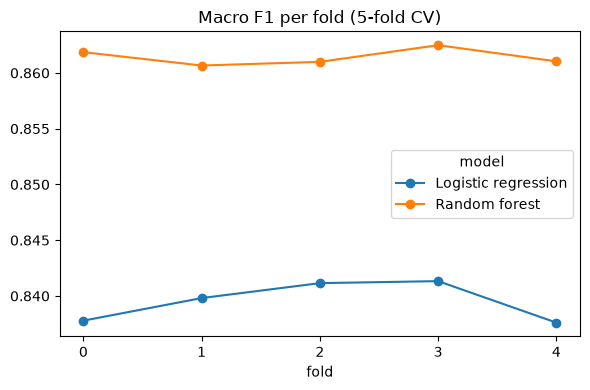

In [16]:
ax = cv_all["f1_macro"].unstack("model").plot(marker="o", figsize=(6, 4), title="Macro F1 per fold (5-fold CV)")
ax.set_xlabel("fold"); ax.set_xticks(range(5)); plt.tight_layout(); plt.savefig(FIG / "cmp_cv.png", dpi=120); plt.show()